# Case study 1 · Multi-class ANN: predicting forest cover type (7 tree species)

**Course file:** `../course-files/Case_Study_ANN_MultiClass_Forest_CoverType.pdf` (the class's Colab notebook) · **Data:** `data/forest_cover_type.csv` (100,000 rows)

**The question:** from a 30 m × 30 m patch of land (elevation, slope, distances to water/roads/fire points, hill shade, wilderness area, soil type), predict which of **7 tree species** covers it.

This notebook **reproduces the class case study step by step** (same split, same scaler, same Keras model, same training settings), explains every step for a beginner, and then asks the questions a good analyst should ask:
- How good is 82% really? (compare with a baseline)
- Why are some species predicted so badly? (class imbalance) Does weighting the classes help?
- Is a neural network even the best tool for this kind of table? (random forest comparison)

Uses **Keras 3 with the PyTorch backend**, exactly like the class notebook (`pip install keras torch scikit-learn pandas seaborn`). The full run takes about 10–12 minutes on a laptop CPU (mostly the two 50-epoch trainings).

In [1]:
%matplotlib inline
import os
os.environ.setdefault("KERAS_BACKEND", "torch")      # Keras 3 can run on PyTorch, TensorFlow or JAX

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, recall_score)
import keras
from keras import layers, models, callbacks

np.random.seed(42); keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "| backend:", keras.backend.backend(), "| pandas", pd.__version__)

Keras 3.13.2 | backend: torch | pandas 3.0.5


## 1 · Load the data and look at the classes

In [2]:
df = pd.read_csv("data/forest_cover_type.csv")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
COVER_TYPE_NAMES = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine", 4: "Cottonwood/Willow",
                    5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}
df["Cover_Type_Name"] = df["Cover_Type"].map(COVER_TYPE_NAMES)
counts = df["Cover_Type"].value_counts().sort_index()
summary = pd.DataFrame({"species": [COVER_TYPE_NAMES[i] for i in counts.index], "count": counts.values,
                        "percent": (100 * counts / len(df)).round(3).values}, index=counts.index)
summary

100,000 rows × 55 columns


,species,count,percent
Cover_Type,,,
1,Spruce/Fir,36460,36.460
2,Lodgepole Pine,48760,48.760
3,Ponderosa Pine,6154,6.154
4,Cottonwood/Willow,473,0.473
5,Aspen,1634,1.634
6,Douglas-fir,2989,2.989
7,Krummholz,3530,3.530


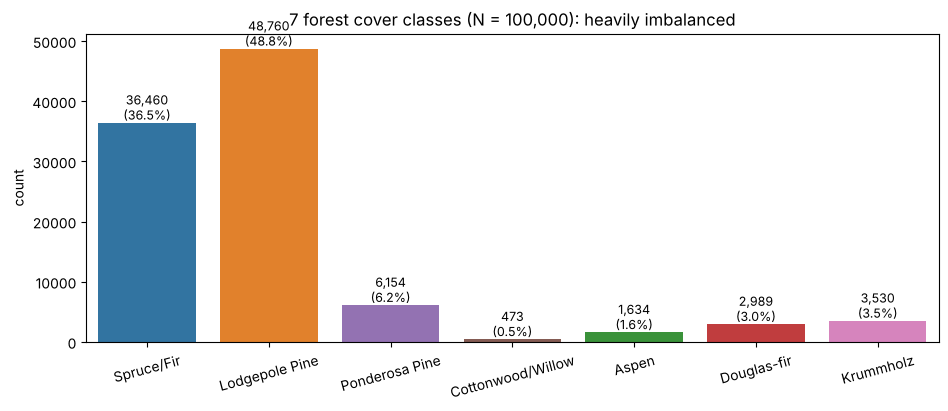

In [3]:
species_order = [COVER_TYPE_NAMES[i] for i in range(1, 8)]
fig, ax = plt.subplots(figsize=(11, 4))
sns.countplot(data=df, x="Cover_Type_Name", order=species_order, hue="Cover_Type_Name", palette="tab10", legend=False, ax=ax)
for p_ in ax.patches:
    ax.annotate(f"{int(p_.get_height()):,}\n({p_.get_height() / len(df):.1%})", (p_.get_x() + p_.get_width() / 2, p_.get_height() + 500), ha="center", fontsize=9)
ax.set_title("7 forest cover classes (N = 100,000): heavily imbalanced"); ax.set_xlabel(""); plt.xticks(rotation=15); plt.show()

**Two species make up 85% of the data** (Lodgepole Pine 48.8%, Spruce/Fir 36.5%), while Cottonwood/Willow is only **0.47%** (473 patches). Keep this in mind: a model can score well overall while almost ignoring the rare species.

> **Baseline to beat:** always answering "Lodgepole Pine" is already **48.76%** accurate.

## 2 · Inspect and clean

In [4]:
print("missing values in the whole table:", int(df.isnull().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
wild = df.filter(like="Wilderness_Area").sum(axis=1); soil = df.filter(like="Soil_Type").sum(axis=1)
print("rows with exactly one wilderness area:", int((wild == 1).sum()), "| exactly one soil type:", int((soil == 1).sum()))
continuous = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
              "Horizontal_Distance_To_Roadways", "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm", "Horizontal_Distance_To_Fire_Points"]
df[continuous].describe().T[["min", "mean", "50%", "max", "std"]].round(1)

missing values in the whole table: 0
duplicate rows: 0


rows with exactly one wilderness area: 100000 | exactly one soil type: 100000


,min,mean,50%,max,std
Elevation,1872.0,2960.1,2997.0,3856.0,279.5
Aspect,0.0,155.7,127.0,360.0,111.8
Slope,0.0,14.1,13.0,61.0,7.5
Horizontal_Distance_To_Hydrology,0.0,269.4,218.0,1397.0,212.2
Vertical_Distance_To_Hydrology,-163.0,46.6,30.0,598.0,58.5
Horizontal_Distance_To_Roadways,0.0,2342.7,1994.0,7063.0,1554.0
Hillshade_9am,0.0,212.1,218.0,254.0,26.9
Hillshade_Noon,0.0,223.3,226.0,254.0,19.8
Hillshade_3pm,0.0,142.6,143.0,253.0,38.4
Horizontal_Distance_To_Fire_Points,0.0,1977.1,1710.0,7172.0,1317.5


- **No missing values, no duplicates.** The 4 wilderness and 40 soil columns are **one-hot**: every row has exactly one 1 in each group, so they're already numeric.
- The 10 continuous features live on **very different scales** (Elevation ~3,000 with spread 280; Slope ~14 with spread 7.5; road distance up to 7,063). That's why we will standardise them (notebook 05: different scales slow down gradient descent).
- **Vertical_Distance_To_Hydrology** can be **negative** (−163): the patch is *below* the water level. That's real, not an error.

## 3 · Explore: what separates the species?

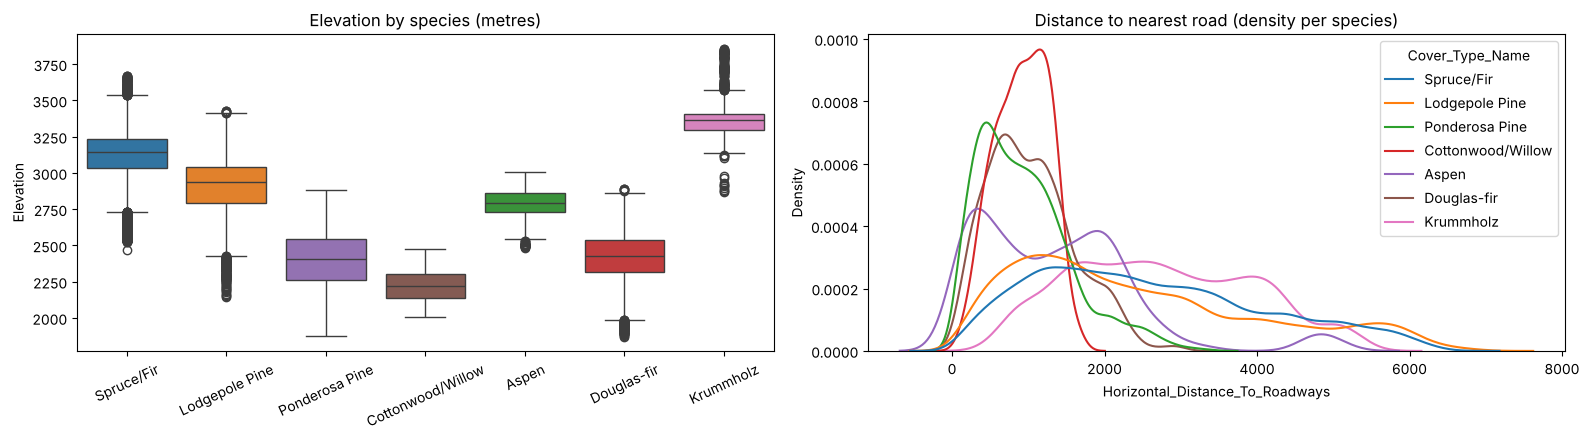

Cover_Type_Name
Spruce/Fir           3146.0
Lodgepole Pine       2936.0
Ponderosa Pine       2405.0
Cottonwood/Willow    2223.0
Aspen                2796.0
Douglas-fir          2427.0
Krummholz            3362.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=df, x="Cover_Type_Name", y="Elevation", order=species_order, hue="Cover_Type_Name", palette="tab10", legend=False, ax=axes[0])
axes[0].set_title("Elevation by species (metres)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=25)
sns.kdeplot(data=df, x="Horizontal_Distance_To_Roadways", hue="Cover_Type_Name", hue_order=species_order,
            common_norm=False, palette="tab10", ax=axes[1])
axes[1].set_title("Distance to nearest road (density per species)")
plt.tight_layout(); plt.show()
print(df.groupby("Cover_Type_Name")["Elevation"].median().reindex(species_order).round(0).to_string())

**Elevation is the strongest single clue** (the case study says the same): Krummholz grows highest (median ≈ 3,360 m), Spruce/Fir next, Cottonwood/Willow lowest (≈ 2,230 m). But several species **overlap** heavily, e.g. Ponderosa Pine and Douglas-fir (both around 2,400 m), and Spruce/Fir and Lodgepole Pine. Expect the model to confuse exactly those pairs.

## 4 · Split, then scale (in that order)

In [6]:
X = df.drop(columns=["Cover_Type", "Cover_Type_Name"])
y = (df["Cover_Type"] - 1).values                       # Keras wants classes 0..6, not 1..7
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"training {X_train.shape[0]:,} × {X_train.shape[1]} features | test {X_test.shape[0]:,}")
print("class shares kept by stratify (train vs test, %):")
print(pd.DataFrame({"train": np.bincount(y_train) / len(y_train) * 100, "test": np.bincount(y_test) / len(y_test) * 100}, index=species_order).round(2).T.to_string())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)          # learn mean/std from TRAINING data only
X_test_scaled = scaler.transform(X_test)                # reuse them on the test data (no leakage)
print("\nafter scaling, training columns have mean ≈", X_train_scaled.mean(0)[:3].round(4), "and std ≈", X_train_scaled.std(0)[:3].round(4))

training 80,000 × 54 features | test 20,000
class shares kept by stratify (train vs test, %):
       Spruce/Fir  Lodgepole Pine  Ponderosa Pine  Cottonwood/Willow  Aspen  Douglas-fir  Krummholz
train       36.46           48.76            6.15               0.47   1.63         2.99       3.53
test        36.46           48.76            6.16               0.47   1.64         2.99       3.53



after scaling, training columns have mean ≈ [-0.  0.  0.] and std ≈ [1. 1. 1.]


- **`stratify=y`** keeps every species' share identical in train and test, which is important when one class is only 0.47%.
- The scaler is **fitted on the training set only** and then applied to the test set. Fitting on all the data would leak information about the test set into training.
- Labels are shifted from 1–7 to **0–6** because `sparse_categorical_crossentropy` expects class indices starting at 0.

## 5 · The model (exactly the case study's)

In [7]:
num_features, num_classes = X_train_scaled.shape[1], 7
def build_model():
    return models.Sequential([
        layers.Input(shape=(num_features,)),
        layers.Dense(128, activation="relu", name="dense_1"),
        layers.BatchNormalization(name="batch_norm_1"),
        layers.Dropout(0.25, name="dropout_1"),
        layers.Dense(64, activation="relu", name="dense_2"),
        layers.Dropout(0.20, name="dropout_2"),
        layers.Dense(32, activation="relu", name="dense_3"),
        layers.Dense(num_classes, activation="softmax", name="output_softmax"),
    ])
keras.utils.set_random_seed(42)
model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         7,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,119 (70.78 KB)

 Trainable params: 17,863 (69.78 KB)

 Non-trainable params: 256 (1.00 KB)

**Where the 18,119 parameters come from** (weights + biases):
- dense_1: 54 × 128 + 128 = **7,040**
- batch_norm_1: 4 × 128 = **512** (γ and β are trained; the running mean and variance are *not* trained, so 256 are "non-trainable")
- dense_2: 128 × 64 + 64 = **8,256**
- dense_3: 64 × 32 + 32 = **2,080**
- output: 32 × 7 + 7 = **231**

Every design choice maps to a chapter: **ReLU** hidden layers (04), **BatchNorm** and **Dropout** (05), **softmax** output for one-of-7 classes (04/06), **sparse categorical cross-entropy** because the labels are integers (06), **Adam** (10), **early stopping** (05).

## 6 · Train (same settings as the case study)

In [8]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
early_stopping = callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1)
history = model.fit(X_train_scaled, y_train, validation_split=0.20, epochs=50, batch_size=128,
                    callbacks=[early_stopping], verbose=0)
h = history.history
best = int(np.argmin(h["val_loss"]))
print(f"ran {len(h['loss'])} epochs; best val_loss {h['val_loss'][best]:.4f} at epoch {best + 1}")
print(f"64,000 training rows / batch 128 = {64000 // 128} weight updates per epoch")
for e in [0, 4, 9, 19, 29, 39, len(h['loss']) - 1]:
    if e < len(h["loss"]):
        print(f"epoch {e + 1:>2}: train acc {h['accuracy'][e]:.4f} loss {h['loss'][e]:.4f} | val acc {h['val_accuracy'][e]:.4f} loss {h['val_loss'][e]:.4f}")

Restoring model weights from the end of the best epoch: 49.


ran 50 epochs; best val_loss 0.3766 at epoch 49
64,000 training rows / batch 128 = 500 weight updates per epoch
epoch  1: train acc 0.6623 loss 0.8082 | val acc 0.7345 loss 0.6307
epoch  5: train acc 0.7443 loss 0.5863 | val acc 0.7732 loss 0.5290
epoch 10: train acc 0.7690 loss 0.5343 | val acc 0.8009 loss 0.4746
epoch 20: train acc 0.7897 loss 0.4895 | val acc 0.8181 loss 0.4343
epoch 30: train acc 0.8002 loss 0.4654 | val acc 0.8356 loss 0.4021
epoch 40: train acc 0.8072 loss 0.4535 | val acc 0.8394 loss 0.3905
epoch 50: train acc 0.8125 loss 0.4445 | val acc 0.8423 loss 0.3800


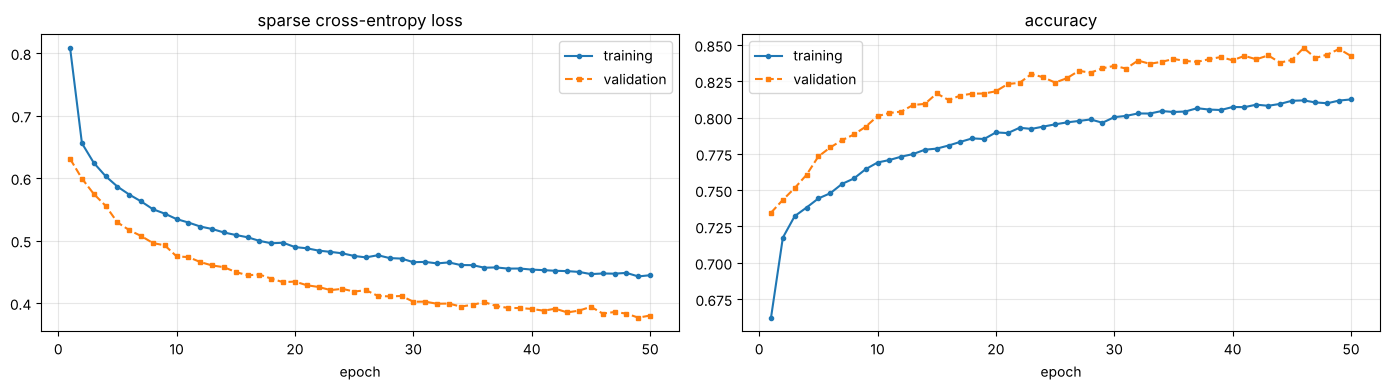

In [9]:
ep = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ep, h["loss"], "o-", ms=3, label="training"); axes[0].plot(ep, h["val_loss"], "s--", ms=3, label="validation")
axes[1].plot(ep, h["accuracy"], "o-", ms=3, label="training"); axes[1].plot(ep, h["val_accuracy"], "s--", ms=3, label="validation")
axes[0].set_title("sparse cross-entropy loss"); axes[1].set_title("accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading the curves:**
- **64,000 training rows ÷ batch 128 = 500 updates per epoch** (the "500/500" in the class log). The other 16,000 training rows are held out for validation by `validation_split=0.2`.
- All 50 epochs ran, and the best validation loss came at **epoch 49**: early stopping never triggered, and **the model was still improving**. Training longer (or with a larger η schedule, chapter 10) would probably help a little.
- **Validation accuracy (0.842) is higher than training accuracy (0.813)** the whole way. That's not a bug: training accuracy is measured **with dropout switched on** (25% and 20% of neurons off) and BatchNorm in batch mode, while validation uses the full network. It's the same effect seen in the class run (val 0.86 vs train 0.82).

> **Note on the class PDF:** its training log shows 50 epochs (best epoch 48), but its loss/accuracy figure only spans **20 epochs** with different values, so the figure must come from a different run than the log above it. Our run reproduces the 50-epoch log's behaviour.

## 7 · Evaluate on the test set (20,000 patches never used in training)

In [10]:
y_pred_probs = model.predict(X_test_scaled, verbose=0)
y_pred = y_pred_probs.argmax(axis=1)
acc, macro_f1, weighted_f1 = accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro"), f1_score(y_test, y_pred, average="weighted")
print(f"overall accuracy {acc:.2%} | macro F1 {macro_f1:.2%} | weighted F1 {weighted_f1:.2%}")
print(f"baseline (always 'Lodgepole Pine'): accuracy {np.mean(y_test == 1):.2%}, macro F1 {f1_score(y_test, np.ones_like(y_test), average='macro'):.2%}")
print()
print(classification_report(y_test, y_pred, target_names=species_order, digits=4))

overall accuracy 84.86% | macro F1 76.23% | weighted F1 84.69%
baseline (always 'Lodgepole Pine'): accuracy 48.76%, macro F1 9.37%

                   precision    recall  f1-score   support

       Spruce/Fir     0.8693    0.8120    0.8397      7292
   Lodgepole Pine     0.8569    0.8999    0.8779      9752
   Ponderosa Pine     0.7933    0.8822    0.8354      1231
Cottonwood/Willow     0.8000    0.6809    0.7356        94
            Aspen     0.7704    0.4618    0.5774       327
      Douglas-fir     0.6880    0.6120    0.6478       598
        Krummholz     0.7883    0.8598    0.8225       706

         accuracy                         0.8486     20000
        macro avg     0.7952    0.7441    0.7623     20000
     weighted avg     0.8483    0.8486    0.8469     20000



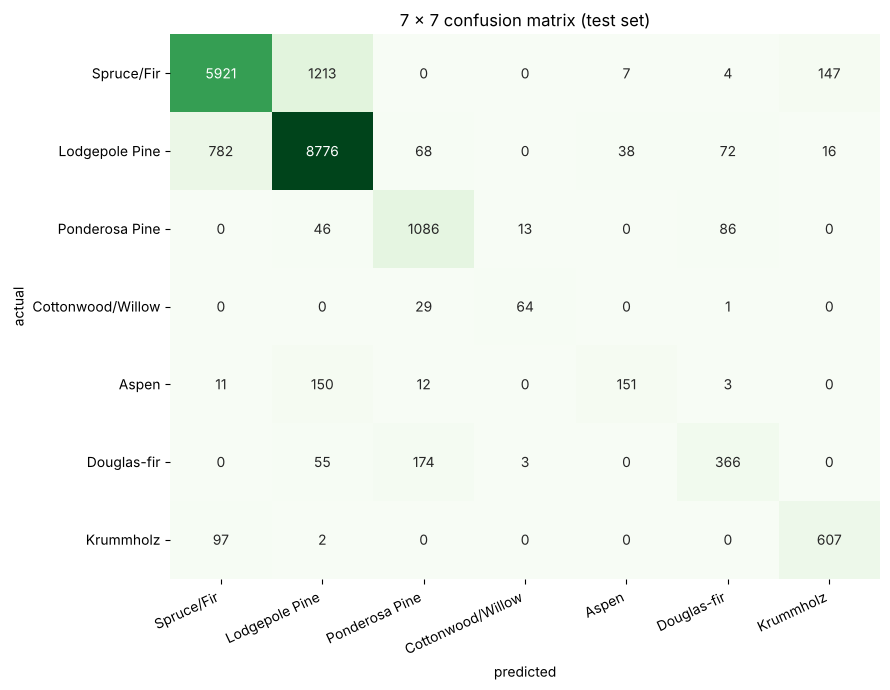

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=species_order, yticklabels=species_order, cbar=False)
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("7 × 7 confusion matrix (test set)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

**Results:**
- **Test accuracy 84.86%**, macro F1 **76.23%**, weighted F1 84.69%. The class run reported 82.25% / 70.97% / 81.97%. Same code, different random initialisation and hardware: **expect a few points of run-to-run variation**, which is why one run is never the final word.
- Against the **48.76% baseline**, the network clearly learned something real (and the baseline's macro F1 is just 9.4%).
- **The big confusion is Spruce/Fir ↔ Lodgepole Pine** (1,213 and 782 test patches mixed up). These are the two big classes with overlapping elevations. **Douglas-fir → Ponderosa Pine** (174) is the other overlap seen in the EDA boxplot.
- **Aspen** is the weakest (recall **0.46**; 150 of the 327 real Aspen patches, almost half, are called Lodgepole Pine). The class run had the same problem (0.34). Cottonwood/Willow (only 94 test patches) reached recall 0.68.

### How to read the metrics (for one class, e.g. Aspen)
- **Precision** = of the patches the model *called* Aspen, how many really were Aspen?
- **Recall** = of the *real* Aspen patches, how many did the model find?
- **F1** = the harmonic mean of the two (high only if both are high).
- **Macro** average = every class counts equally (rare species matter as much as common ones). **Weighted** average = classes count by their size (dominated by the two big species).

That's why **macro F1 is much lower than accuracy** here: the model is good on the big classes and weak on some rare ones.

## 8 · One-vs-rest ROC curves
For each species, treat it as "this species vs all others" and sweep the decision threshold.

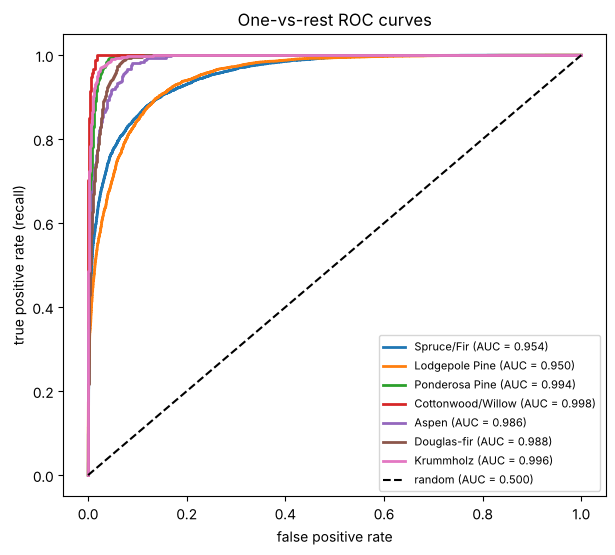

In [12]:
y_test_bin = label_binarize(y_test, classes=range(7))
plt.figure(figsize=(7, 6))
for i, name in enumerate(species_order):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test_bin[:, i], y_pred_probs[:, i]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random (AUC = 0.500)")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate (recall)"); plt.legend(fontsize=8, loc="lower right")
plt.title("One-vs-rest ROC curves"); plt.show()

Every species has an AUC between **0.950** (Lodgepole Pine) and **0.998** (Cottonwood/Willow), against 0.500 for guessing. This shows that the model **ranks** patches well even for classes with poor recall: Aspen's AUC is 0.986, but its recall at the default argmax decision is only 0.46. **The probabilities are informative; the decision rule (pick the largest) is what hurts the rare classes.** Lodgepole and Spruce/Fir have the lowest AUCs because they are the most confused pair.

## 9 · Using the model: top-3 predictions for new patches

In [13]:
def predict_forest_cover(sample_df, model, scaler, feature_names):
    scaled = scaler.transform(sample_df.reindex(columns=feature_names, fill_value=0.0))
    probs = model.predict(scaled, verbose=0)
    for n, p_ in enumerate(probs, 1):
        top3 = np.argsort(p_)[::-1][:3]
        print(f"location #{n}:")
        for rank, c in enumerate(top3, 1):
            print(f"   {rank}. {species_order[c]:<18} {p_[c]:6.2%} {'█' * int(p_[c] * 25)}")
    return probs

samples = X_test.iloc[[0, 15, 30]]
_ = predict_forest_cover(samples, model, scaler, X_train.columns.tolist())
print("true species:", [species_order[i] for i in y_test[[0, 15, 30]]])

location #1:
   1. Lodgepole Pine     97.77% ████████████████████████
   2. Spruce/Fir          2.12% 
   3. Aspen               0.11% 
location #2:
   1. Spruce/Fir         66.39% ████████████████
   2. Lodgepole Pine     33.35% ████████
   3. Krummholz           0.25% 
location #3:
   1. Lodgepole Pine     78.37% ███████████████████
   2. Aspen              18.53% ████
   3. Spruce/Fir          2.42% 
true species: ['Lodgepole Pine', 'Lodgepole Pine', 'Lodgepole Pine']


## 10 · Can we do better for the rare species? Class weights
The loss treats every training row equally, so the 0.47% class barely affects it. **Class weights** multiply each class's loss: rare classes count more.
- **balanced:** weight = (number of rows) / (7 × rows of that class), so each class contributes equally overall (Cottonwood/Willow ×30);
- **sqrt:** the square root of those weights, a gentler push.

Same model and settings otherwise.

In [14]:
counts_tr = np.bincount(y_train)
balanced = {i: len(y_train) / (7 * c) for i, c in enumerate(counts_tr)}
gentle = {i: float(np.sqrt(w)) for i, w in balanced.items()}           # square root: a milder push
print("balanced weights:", {species_order[i]: round(float(w), 2) for i, w in balanced.items()})
print("sqrt weights    :", {species_order[i]: round(w, 2) for i, w in gentle.items()})

def fit_weighted(cw):
    keras.utils.set_random_seed(42)
    m = build_model()
    m.compile(optimizer=keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = m.fit(X_train_scaled, y_train, validation_split=0.20, epochs=50, batch_size=128, class_weight=cw,
                 callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)], verbose=0)
    return m.predict(X_test_scaled, verbose=0).argmax(1), len(hist.history["loss"])

y_pred_w, n_bal = fit_weighted(balanced)
y_pred_g, n_gen = fit_weighted(gentle)
print(f"\nepochs run: balanced {n_bal}, sqrt {n_gen}")
cmp = pd.DataFrame({"recall: no weights": recall_score(y_test, y_pred, average=None),
                    "recall: sqrt weights": recall_score(y_test, y_pred_g, average=None),
                    "recall: balanced weights": recall_score(y_test, y_pred_w, average=None)}, index=species_order).round(3)
print(cmp.to_string())
for name, yp in [("no weights", y_pred), ("sqrt weights", y_pred_g), ("balanced weights", y_pred_w)]:
    print(f"{name:<17} accuracy {accuracy_score(y_test, yp):.2%}   macro F1 {f1_score(y_test, yp, average='macro'):.2%}")

balanced weights: {'Spruce/Fir': 0.39, 'Lodgepole Pine': 0.29, 'Ponderosa Pine': 2.32, 'Cottonwood/Willow': 30.15, 'Aspen': 8.74, 'Douglas-fir': 4.78, 'Krummholz': 4.05}
sqrt weights    : {'Spruce/Fir': 0.63, 'Lodgepole Pine': 0.54, 'Ponderosa Pine': 1.52, 'Cottonwood/Willow': 5.49, 'Aspen': 2.96, 'Douglas-fir': 2.19, 'Krummholz': 2.01}



epochs run: balanced 27, sqrt 27
                   recall: no weights  recall: sqrt weights  recall: balanced weights
Spruce/Fir                      0.812                 0.792                     0.773
Lodgepole Pine                  0.900                 0.784                     0.571
Ponderosa Pine                  0.882                 0.787                     0.570
Cottonwood/Willow               0.681                 0.755                     0.957
Aspen                           0.462                 0.752                     0.945
Douglas-fir                     0.612                 0.707                     0.804
Krummholz                       0.860                 0.882                     0.942
no weights        accuracy 84.86%   macro F1 76.23%
sqrt weights      accuracy 78.75%   macro F1 70.76%
balanced weights  accuracy 67.26%   macro F1 58.01%


**Honest reading:**
- Class weights did what they promise for the **rare** species: Aspen recall went 0.46 → **0.75** (sqrt) → **0.95** (balanced), and Cottonwood/Willow 0.68 → 0.76 → **0.96**.
- But the **common** species paid heavily: Lodgepole Pine recall fell 0.90 → 0.78 → **0.57**. Overall accuracy dropped to 78.8% (sqrt) and **67.3%** (balanced), and even **macro F1 fell** (76.2% → 70.8% → 58.0%), because the rare classes are now **over-predicted** (their precision collapses).
- **Lesson:** class weighting is a **trade-off dial**, not a free improvement. Fully balanced weights (×30 for Cottonwood) were far too strong here. Whether the trade is worth it depends on the cost of missing a rare species versus mislabelling a common one, and you should tune the weights (or the decision thresholds) on **validation** data.

## 11 · Is a neural network the right tool here? A random-forest comparison
For **tabular** data (rows and columns of measurements), tree ensembles are a very strong baseline. Same split, no scaling needed (trees don't care about scale).

In [15]:
import time
from sklearn.ensemble import RandomForestClassifier
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f"random forest: trained in {time.time() - t0:.0f} s | accuracy {accuracy_score(y_test, y_pred_rf):.2%} | macro F1 {f1_score(y_test, y_pred_rf, average='macro'):.2%}")
print("per-class recall:", dict(zip(species_order, recall_score(y_test, y_pred_rf, average=None).round(3))))
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\ntop 5 features by random-forest importance:\n" + imp.head(5).round(3).to_string())

random forest: trained in 4 s | accuracy 90.68% | macro F1 83.87%
per-class recall: {'Spruce/Fir': np.float64(0.89), 'Lodgepole Pine': np.float64(0.945), 'Ponderosa Pine': np.float64(0.92), 'Cottonwood/Willow': np.float64(0.723), 'Aspen': np.float64(0.498), 'Douglas-fir': np.float64(0.747), 'Krummholz': np.float64(0.881)}

top 5 features by random-forest importance:
Elevation                             0.232
Horizontal_Distance_To_Roadways       0.105
Horizontal_Distance_To_Fire_Points    0.097
Horizontal_Distance_To_Hydrology      0.061
Vertical_Distance_To_Hydrology        0.060


**The random forest won clearly:** **90.68%** accuracy and **83.87%** macro F1, trained in **4 seconds**, against the ANN's 84.86% / 76.23% after ~5 minutes. It also agrees with the EDA: **Elevation** is by far its most important feature (0.232), followed by the distances to roads and fire points.

This is a well-known pattern, not a fluke: on **tabular** data with mixed, non-smooth features (thresholds on elevation, one-hot soil types), tree ensembles are usually as good as or better than plain MLPs, and much cheaper. Neural networks win on images, audio and text, where they learn the features themselves.

## 12 · Summary

| Model | Test accuracy | Macro F1 |
|---|---|---|
| always "Lodgepole Pine" | 48.76% | 9.37% |
| **case-study ANN (this run)** | **84.86%** | **76.23%** |
| case-study ANN (class PDF run) | 82.25% | 70.97% |
| ANN + sqrt class weights | 78.75% | 70.76% |
| ANN + balanced class weights | 67.26% | 58.01% |
| random forest (100 trees, 4 s) | **90.68%** | **83.87%** |

**Lessons for the viva:**
1. **Always compare with a baseline.** 48.8% for free; the ANN's job is the gap above that.
2. **Accuracy hides rare classes.** Look at macro F1, per-class recall and the confusion matrix.
3. **Split before scaling; fit the scaler on train only; stratify** imbalanced classes.
4. **Validation accuracy above training accuracy** is normal with dropout (and BatchNorm): training metrics are measured with neurons switched off.
5. **Class weights** raise rare-class recall but cost common-class recall and precision. Here even macro F1 fell, so tune the strength on validation data.
6. **For tabular data, try a tree ensemble**: here it beat the case study's ANN clearly (90.7% vs 84.9%, in 4 s). Neural networks shine on images, audio and text; on tables, the honest answer is "compare".

## ✅ Check yourself
1. Why are labels shifted from 1–7 to 0–6? *(sparse categorical cross-entropy expects class indices 0…K−1)*
2. Why `stratify=y`? *(keeps each class's share equal in train and test; vital for 0.47% classes)*
3. Why fit the scaler on the training set only? *(fitting on all data leaks test information)*
4. dense_1 has 7,040 parameters. Show the calculation. *(54 × 128 weights + 128 biases)*
5. The class run had accuracy 82% but macro F1 71%. What does the gap tell you? *(rare classes are predicted much worse than common ones)*
6. Why could validation accuracy be higher than training accuracy? *(dropout is active when training metrics are computed, but off for validation)*
7. Aspen had recall 0.34 in the class run (0.46 in ours). What does that mean in words? *(the model finds only about a third of the real Aspen patches)*